# Lista 2: Inteligência Artificial (UFAL)
## Questão 2: K-Vizinhos Mais Próximos (KNN)

**Dupla:**
- Bruno Gomes de Barros Filho, matrícula 21111360
- Antônio Rodrigo Lima de Andrade Tenório, matrícula 23210707

**Disciplina:** ECOM031: Inteligência Artificial
**Professor:** Evandro de Barros Costa
**Período:** 2026.2

---

### Enunciado (Q2)
> Mostre e explique o funcionamento do algoritmo dos K-vizinhos mais próximos (KNN)
> sobre a base de dados com as **30 instâncias** que você usou na lista de exercício 1.

**Base da Lista 1:** risco de crédito (Luger), ampliada para 6 atributos e 30 exemplos (E1 a E30),
com classes de risco Alto, Moderado e Baixo.


---
## 0. Instalação e imports


In [1]:
import subprocess, sys
pkgs = ['scikit-learn', 'pandas', 'numpy', 'matplotlib', 'seaborn']
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + pkgs)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#1baf7a'
# Ordem do LabelEncoder alfabética: Alto, Baixo, Moderado
PALETTE = [ORANGE, GREEN, BLUE]
RANDOM_STATE = 42

print('✓ Imports OK')



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Users/bruno/Documents/projects/ufal/lista2-ia-ufal/venv/bin/python -m pip install --upgrade pip


✓ Imports OK


---
## 1. As 30 instâncias da Lista 1

A Questão 1 da Lista 1 pediu a ampliação da base de risco de crédito do Luger para
6 atributos e 30 exemplos. Os atributos são História de Crédito, Dívida, Garantia,
Renda, Emprego e Imóvel. O alvo é o risco: Alto, Moderado ou Baixo.

Abaixo está a mesma tabela usada na Lista 1 (E1 a E30).


In [2]:
raw = '''E1 Ruim Alta Nenhuma 0-15 Instavel Alugado Alto
E2 Desconhecida Alta Nenhuma 15-35 Instavel Alugado Alto
E3 Desconhecida Baixa Nenhuma 15-35 Estavel Alugado Moderado
E4 Desconhecida Baixa Nenhuma 0-15 Instavel Alugado Alto
E5 Desconhecida Baixa Nenhuma >35 Estavel Proprio Baixo
E6 Desconhecida Baixa Adequada >35 Estavel Proprio Baixo
E7 Ruim Baixa Nenhuma 0-15 Instavel Alugado Alto
E8 Ruim Baixa Adequada >35 Estavel Alugado Moderado
E9 Boa Baixa Nenhuma >35 Estavel Proprio Baixo
E10 Boa Alta Adequada >35 Estavel Proprio Baixo
E11 Boa Alta Nenhuma 0-15 Instavel Alugado Alto
E12 Boa Alta Nenhuma 15-35 Estavel Alugado Moderado
E13 Boa Alta Nenhuma >35 Estavel Alugado Baixo
E14 Ruim Alta Nenhuma 15-35 Instavel Alugado Alto
E15 Boa Baixa Adequada 15-35 Estavel Proprio Baixo
E16 Boa Baixa Nenhuma 15-35 Estavel Proprio Baixo
E17 Desconhecida Baixa Adequada >35 Instavel Proprio Moderado
E18 Ruim Alta Nenhuma >35 Estavel Alugado Moderado
E19 Desconhecida Alta Nenhuma 0-15 Estavel Alugado Alto
E20 Boa Baixa Adequada >35 Estavel Alugado Baixo
E21 Ruim Baixa Nenhuma 15-35 Estavel Alugado Moderado
E22 Boa Alta Adequada 15-35 Estavel Proprio Moderado
E23 Ruim Alta Adequada 0-15 Instavel Proprio Alto
E24 Desconhecida Baixa Nenhuma 15-35 Instavel Proprio Moderado
E25 Boa Baixa Nenhuma 0-15 Estavel Proprio Moderado
E26 Ruim Baixa Nenhuma >35 Instavel Alugado Alto
E27 Desconhecida Alta Adequada >35 Estavel Proprio Baixo
E28 Ruim Alta Nenhuma 15-35 Estavel Alugado Alto
E29 Boa Baixa Nenhuma >35 Instavel Proprio Baixo
E30 Desconhecida Baixa Nenhuma 0-15 Estavel Alugado Alto'''

linhas = [l.split() for l in raw.strip().split('\n')]
cols = ['Historia', 'Divida', 'Garantia', 'Renda', 'Emprego', 'Imovel', 'Risco']
df30 = pd.DataFrame(
    [l[1:] for l in linhas],
    columns=cols,
    index=[l[0] for l in linhas],
).astype(object)

atributos = cols[:-1]
print(f'Exemplos: {len(df30)} | Atributos: {len(atributos)}')
print('Distribuição das classes:', df30['Risco'].value_counts().to_dict())
df30

Exemplos: 30 | Atributos: 6
Distribuição das classes: {'Alto': 11, 'Baixo': 10, 'Moderado': 9}


,Historia,Divida,Garantia,Renda,Emprego,Imovel,Risco
E1,Ruim,Alta,Nenhuma,0-15,Instavel,Alugado,Alto
E2,Desconhecida,Alta,Nenhuma,15-35,Instavel,Alugado,Alto
E3,Desconhecida,Baixa,Nenhuma,15-35,Estavel,Alugado,Moderado
E4,Desconhecida,Baixa,Nenhuma,0-15,Instavel,Alugado,Alto
E5,Desconhecida,Baixa,Nenhuma,>35,Estavel,Proprio,Baixo
E6,Desconhecida,Baixa,Adequada,>35,Estavel,Proprio,Baixo
E7,Ruim,Baixa,Nenhuma,0-15,Instavel,Alugado,Alto
E8,Ruim,Baixa,Adequada,>35,Estavel,Alugado,Moderado
E9,Boa,Baixa,Nenhuma,>35,Estavel,Proprio,Baixo
E10,Boa,Alta,Adequada,>35,Estavel,Proprio,Baixo


---
## 2. Pré-processamento para o KNN

Os atributos são categóricos. Para calcular distância euclidiana, cada atributo vira
colunas binárias com *one-hot encoding* (`get_dummies`), o mesmo tipo de representação
usada no CART da Lista 1. Como as features ficam em {0, 1}, não há normalização extra.

O alvo `Risco` é codificado numericamente só para o scikit-learn; nas tabelas e gráficos
continuamos com os nomes Alto, Baixo e Moderado.


Dimensão após one-hot: (30, 14)
Ordem das classes (LabelEncoder): ['Alto', 'Baixo', 'Moderado']
Features: ['Historia_Boa', 'Historia_Desconhecida', 'Historia_Ruim', 'Divida_Alta', 'Divida_Baixa', 'Garantia_Adequada', 'Garantia_Nenhuma', 'Renda_0-15', 'Renda_15-35', 'Renda_>35', 'Emprego_Estavel', 'Emprego_Instavel', 'Imovel_Alugado', 'Imovel_Proprio']


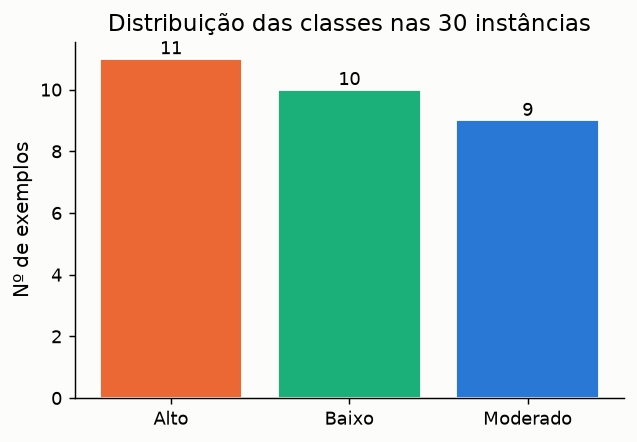

In [3]:
X_df = pd.get_dummies(df30[atributos]).astype(int)
feature_names = list(X_df.columns)
X = X_df.values

le = LabelEncoder()
y = le.fit_transform(df30['Risco'])

print('Dimensão após one-hot:', X.shape)
print('Ordem das classes (LabelEncoder):', list(le.classes_))
print('Features:', feature_names)

counts = pd.Series(df30['Risco']).value_counts().reindex(le.classes_)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=PALETTE, edgecolor='white')
ax.set_ylabel('Nº de exemplos')
ax.set_title('Distribuição das classes nas 30 instâncias')
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.15, str(v), ha='center')
plt.tight_layout()
plt.show()


### Tabela das 30 instâncias


In [4]:
df_export = df30.copy()
df_export.index.name = 'Exemplo'
df_export


,Historia,Divida,Garantia,Renda,Emprego,Imovel,Risco
Exemplo,,,,,,,
E1,Ruim,Alta,Nenhuma,0-15,Instavel,Alugado,Alto
E2,Desconhecida,Alta,Nenhuma,15-35,Instavel,Alugado,Alto
E3,Desconhecida,Baixa,Nenhuma,15-35,Estavel,Alugado,Moderado
E4,Desconhecida,Baixa,Nenhuma,0-15,Instavel,Alugado,Alto
E5,Desconhecida,Baixa,Nenhuma,>35,Estavel,Proprio,Baixo
E6,Desconhecida,Baixa,Adequada,>35,Estavel,Proprio,Baixo
E7,Ruim,Baixa,Nenhuma,0-15,Instavel,Alugado,Alto
E8,Ruim,Baixa,Adequada,>35,Estavel,Alugado,Moderado
E9,Boa,Baixa,Nenhuma,>35,Estavel,Proprio,Baixo


---
## 3. Escolha do hiperparâmetro k (LOO-CV)

Com só 30 exemplos, Leave-One-Out é a validação natural: a cada rodada, um exemplo
fica de fora para teste e os outros 29 treinam o modelo. Testamos k ímpar em
{1, 3, 5, 7, 9} para reduzir empate no voto.


In [5]:
k_values = [1, 3, 5, 7, 9]
loo = LeaveOneOut()
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    acc = cross_val_score(knn, X, y, cv=loo).mean()
    scores.append(acc)
    print(f'k={k}: acurácia LOO-CV = {acc:.1%} ({acc*len(y):.0f}/{len(y)})')

best_k = k_values[int(np.argmax(scores))]
print(f'\nMelhor k: {best_k} (acurácia {max(scores):.1%})')

k=1: acurácia LOO-CV = 60.0% (18/30)
k=3: acurácia LOO-CV = 63.3% (19/30)
k=5: acurácia LOO-CV = 70.0% (21/30)
k=7: acurácia LOO-CV = 63.3% (19/30)
k=9: acurácia LOO-CV = 60.0% (18/30)

Melhor k: 5 (acurácia 70.0%)


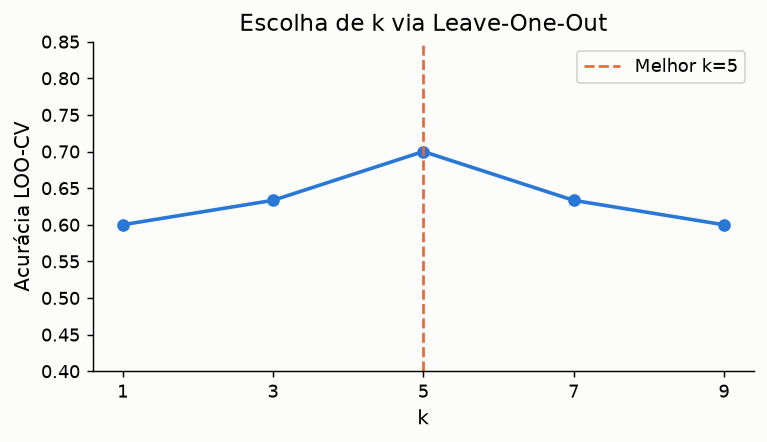

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k_values, scores, marker='o', color=BLUE, linewidth=2)
ax.axvline(best_k, color=ORANGE, linestyle='--', label=f'Melhor k={best_k}')
ax.set_xticks(k_values)
ax.set_xlabel('k')
ax.set_ylabel('Acurácia LOO-CV')
ax.set_title('Escolha de k via Leave-One-Out')
ax.set_ylim(0.4, 0.85)
ax.legend()
plt.tight_layout()
plt.show()


---
## 4. Avaliação com o melhor k

As predições abaixo também usam Leave-One-Out, para ficar alinhadas com a escolha de k.


In [7]:
y_pred = np.empty_like(y)
for train_idx, test_idx in loo.split(X):
    knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
    knn.fit(X[train_idx], y[train_idx])
    y_pred[test_idx] = knn.predict(X[test_idx])

print(classification_report(y, y_pred, target_names=le.classes_))
print(f'KNN com k={best_k} avaliado em LOO-CV sobre as {len(X)} instâncias.')

              precision    recall  f1-score   support

        Alto       0.71      0.91      0.80        11
       Baixo       0.71      1.00      0.83        10
    Moderado       0.50      0.11      0.18         9

    accuracy                           0.70        30
   macro avg       0.64      0.67      0.61        30
weighted avg       0.65      0.70      0.63        30

KNN com k=5 avaliado em LOO-CV sobre as 30 instâncias.


---
## 5. Exemplo passo a passo: classificando E1

Pegamos o exemplo E1 (risco real Alto), treinamos com os outros 29 e mostramos
os k vizinhos mais próximos, as distâncias e o voto majoritário.


In [8]:
QUERY_ID = 'E1'
QUERY_IDX = list(df30.index).index(QUERY_ID)

X_train_ex = np.delete(X, QUERY_IDX, axis=0)
y_train_ex = np.delete(y, QUERY_IDX)
ids_train = np.delete(np.array(df30.index), QUERY_IDX)

knn_ex = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_ex.fit(X_train_ex, y_train_ex)

q = X[QUERY_IDX].reshape(1, -1)
neigh_dist, neigh_pos = knn_ex.kneighbors(q, n_neighbors=best_k, return_distance=True)
neigh_dist, neigh_pos = neigh_dist[0], neigh_pos[0]
pred = knn_ex.predict(q)[0]

print(f'Instância-query: {QUERY_ID}')
print(df30.loc[QUERY_ID].to_string())
print()
print(f'Vetor one-hot ({len(feature_names)} dims):')
print(dict(zip(feature_names, X[QUERY_IDX].tolist())))
print()
print(f'{best_k} vizinhos mais próximos:')
for rank, (d, pos) in enumerate(zip(neigh_dist, neigh_pos), 1):
    eid = ids_train[pos]
    risco = le.inverse_transform([y_train_ex[pos]])[0]
    print(f'  {rank}. {eid}  dist={d:.3f}  risco={risco}')

from collections import Counter
votos = Counter(le.inverse_transform(y_train_ex[neigh_pos]))
print()
print('Votos:', dict(votos))
print(
    f'Classe predita: {le.inverse_transform([pred])[0]} | '
    f'Classe real: {df30.loc[QUERY_ID, "Risco"]}'
)

distances_full = np.linalg.norm(X_train_ex - X[QUERY_IDX], axis=1)
sorted_idx = np.argsort(distances_full)

Instância-query: E1
Historia        Ruim
Divida          Alta
Garantia     Nenhuma
Renda           0-15
Emprego     Instavel
Imovel       Alugado
Risco           Alto

Vetor one-hot (14 dims):
{'Historia_Boa': 0, 'Historia_Desconhecida': 0, 'Historia_Ruim': 1, 'Divida_Alta': 1, 'Divida_Baixa': 0, 'Garantia_Adequada': 0, 'Garantia_Nenhuma': 1, 'Renda_0-15': 1, 'Renda_15-35': 0, 'Renda_>35': 0, 'Emprego_Estavel': 0, 'Emprego_Instavel': 1, 'Imovel_Alugado': 1, 'Imovel_Proprio': 0}

5 vizinhos mais próximos:
  1. E7  dist=1.414  risco=Alto
  2. E11  dist=1.414  risco=Alto
  3. E14  dist=1.414  risco=Alto
  4. E2  dist=2.000  risco=Alto
  5. E4  dist=2.000  risco=Alto

Votos: {'Alto': 5}
Classe predita: Alto | Classe real: Alto


---
## 6. Visualizações

### 6.1 Matriz de confusão


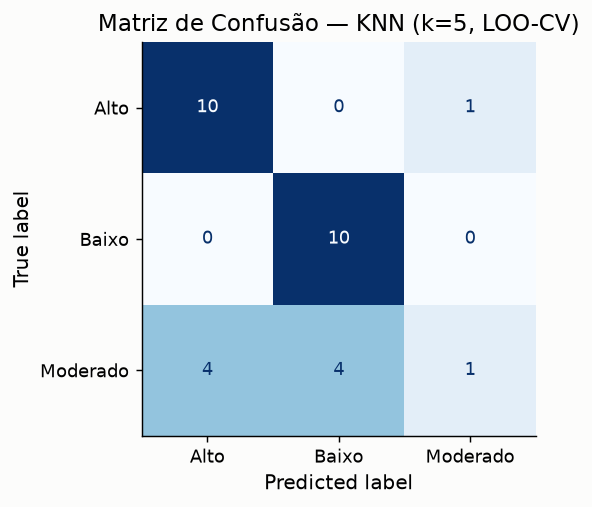

In [9]:
cm = confusion_matrix(y, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Matriz de Confusão — KNN (k={best_k}, LOO-CV)')
plt.tight_layout()
plt.show()


### 6.2 Fronteira de decisão projetada via PCA (2D)


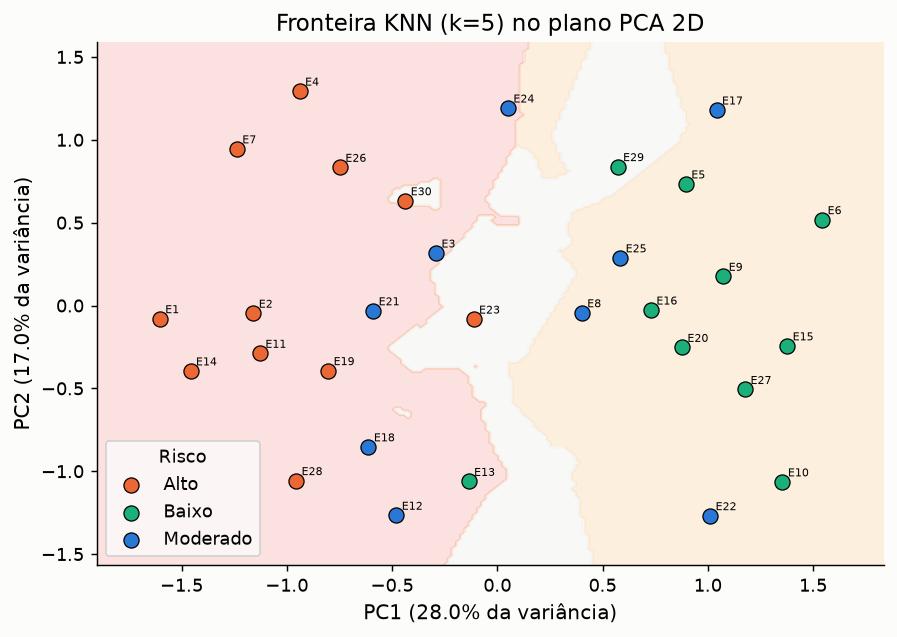

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
explained = pca.explained_variance_ratio_

knn_2d = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_2d.fit(X_2d, y)

h = 0.02
x_min, x_max = X_2d[:, 0].min() - 0.3, X_2d[:, 0].max() + 0.3
y_min, y_max = X_2d[:, 1].min() - 0.3, X_2d[:, 1].max() + 0.3
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
cmap_light = plt.colormaps['Pastel1'].resampled(3)
ax.contourf(xx, yy, Z, alpha=0.35, cmap=cmap_light)

for ci, (cls, color) in enumerate(zip(le.classes_, PALETTE)):
    mask = y == ci
    ax.scatter(
        X_2d[mask, 0], X_2d[mask, 1],
        color=color, edgecolors='k', s=70, linewidths=0.7,
        label=cls, zorder=3,
    )

for i, eid in enumerate(df30.index):
    ax.annotate(
        eid, (X_2d[i, 0], X_2d[i, 1]), fontsize=6,
        xytext=(3, 3), textcoords='offset points',
    )

ax.set_xlabel(f'PC1 ({explained[0]*100:.1f}% da variância)')
ax.set_ylabel(f'PC2 ({explained[1]*100:.1f}% da variância)')
ax.set_title(f'Fronteira KNN (k={best_k}) no plano PCA 2D')
ax.legend(title='Risco')
plt.tight_layout()
plt.show()


### 6.3 Distâncias aos vizinhos da instância-query


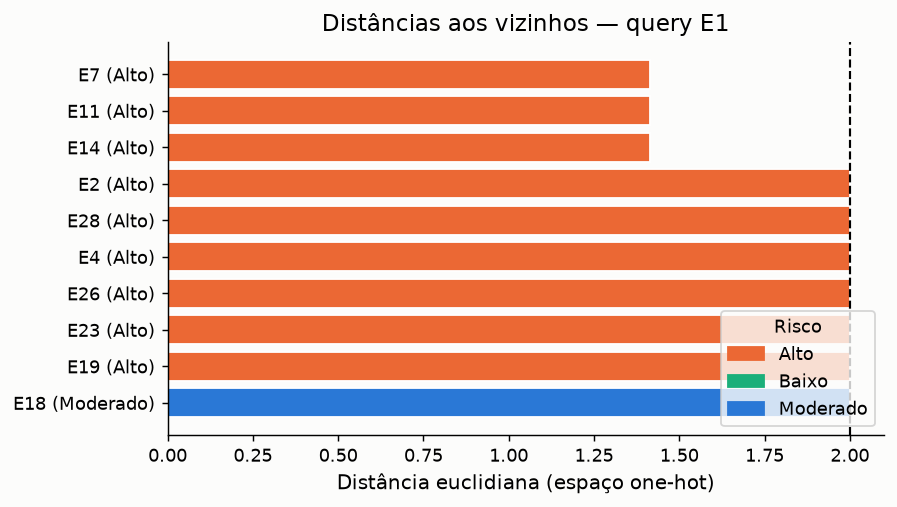

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
top_n = min(10, len(X_train_ex))
top_dists = distances_full[sorted_idx[:top_n]]
top_labels = [le.classes_[y_train_ex[i]] for i in sorted_idx[:top_n]]
top_ids = [ids_train[i] for i in sorted_idx[:top_n]]
top_colors = [PALETTE[le.transform([lbl])[0]] for lbl in top_labels]

ax.barh(range(top_n), top_dists, color=top_colors, edgecolor='white')
ax.axvline(
    top_dists[best_k - 1] + 1e-6,
    color='black', linestyle='--', linewidth=1.2,
    label=f'Corte k={best_k}',
)
ax.set_yticks(range(top_n))
ax.set_yticklabels([f'{top_ids[i]} ({top_labels[i]})' for i in range(top_n)])
ax.invert_yaxis()
ax.set_xlabel('Distância euclidiana (espaço one-hot)')
ax.set_title(f'Distâncias aos vizinhos — query {QUERY_ID}')

patches = [
    mpatches.Patch(color=PALETTE[i], label=cls)
    for i, cls in enumerate(le.classes_)
]
ax.legend(handles=patches, title='Risco', loc='lower right')
plt.tight_layout()
plt.show()


---
## 7. Resumo dos resultados


In [12]:
print(f'Base: risco de crédito (Lista 1) — {len(df30)} exemplos (E1–E30)')
print(f'Atributos: {", ".join(atributos)}')
print(f'Codificação: one-hot → {X.shape[1]} dimensões')
print(f'Melhor k (LOO-CV): {best_k}')
print(f'Acurácia LOO-CV: {max(scores):.1%}')
print()
report = classification_report(
    y, y_pred, target_names=le.classes_, output_dict=True
)
for cls in le.classes_:
    r = report[cls]
    print(
        f'{cls:<8} → P={r["precision"]:.2f}  R={r["recall"]:.2f}  '
        f'F1={r["f1-score"]:.2f}  Sup={int(r["support"])}'
    )
print(f'Acurácia geral: {report["accuracy"]:.1%}')


Base: risco de crédito (Lista 1) — 30 exemplos (E1–E30)
Atributos: Historia, Divida, Garantia, Renda, Emprego, Imovel
Codificação: one-hot → 14 dimensões
Melhor k (LOO-CV): 5
Acurácia LOO-CV: 70.0%

Alto     → P=0.71  R=0.91  F1=0.80  Sup=11
Baixo    → P=0.71  R=1.00  F1=0.83  Sup=10
Moderado → P=0.50  R=0.11  F1=0.18  Sup=9
Acurácia geral: 70.0%
